In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

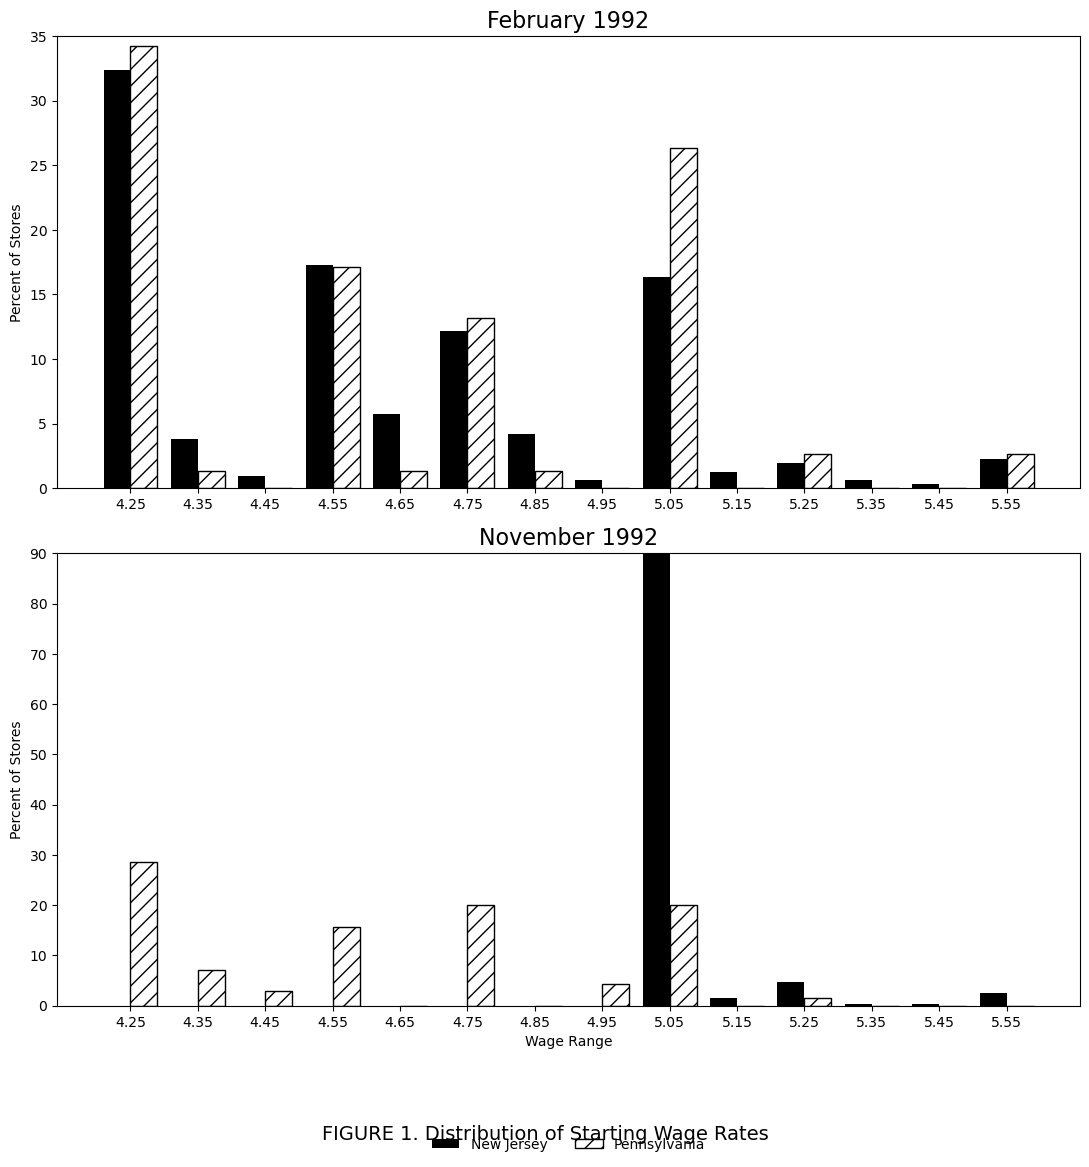

In [5]:
df = pd.read_stata(r"C:\Users\Lenovo\Desktop\6067\01_DID\data\cardkrueger_clean.dta")

def get_wage_dist(df_sub, wage_var):
    df_sub = df_sub.dropna(subset=[wage_var]).copy()
    bins = np.arange(4.2, 5.7, 0.1)
    bin_labels = np.arange(4.25, 5.6, 0.1)
    df_sub["wage_bin"] = pd.cut(df_sub[wage_var], bins=bins, labels=bin_labels)
    cnt = df_sub.groupby(["state", "wage_bin"]).size().reset_index(name="n")
    cnt["pct"] = 100 * cnt["n"] / cnt.groupby("state")["n"].transform("sum")
    all_bin_df = pd.DataFrame({"wage_bin": bin_labels})
    nj = all_bin_df.merge(cnt[cnt["state"]==1], on="wage_bin", how="left").fillna({"pct":0})
    pa = all_bin_df.merge(cnt[cnt["state"]==0], on="wage_bin", how="left").fillna({"pct":0})
    return nj, pa, bin_labels

fig, (ax1, ax2) = plt.subplots(2,1, figsize=(11,12))
bw = 0.04

# Feb 1992 wave1 wage_st
nj1, pa1, x_ticks = get_wage_dist(df, "wage_st")
ax1.bar(x_ticks - bw/2, nj1["pct"], width=bw, color="black")
ax1.bar(x_ticks + bw/2, pa1["pct"], width=bw, facecolor="white", edgecolor="black", hatch="//")
ax1.set_title("February 1992", fontsize=16)
ax1.set_ylabel("Percent of Stores")
ax1.set_xticks(x_ticks)
ax1.set_ylim(0,35)

# Nov 1992 wave2 wage_st2
nj2, pa2, x_ticks2 = get_wage_dist(df, "wage_st2")
ax2.bar(x_ticks2 - bw/2, nj2["pct"], width=bw, color="black", label="New Jersey")
ax2.bar(x_ticks2 + bw/2, pa2["pct"], width=bw, facecolor="white", edgecolor="black", hatch="//", label="Pennsylvania")
ax2.set_title("November 1992", fontsize=16)
ax2.set_xlabel("Wage Range")
ax2.set_ylabel("Percent of Stores")
ax2.set_xticks(x_ticks2)
ax2.set_ylim(0,90)
ax2.legend(loc="lower center", bbox_to_anchor=(0.5,-0.35), ncol=2, frameon=False)

fig.suptitle("FIGURE 1. Distribution of Starting Wage Rates", y=0.03, fontsize=14)
plt.tight_layout()
plt.savefig(r"C:\Users\Lenovo\Desktop\6067\01_DID\figure1_cardkrueger.pdf", bbox_inches="tight")
plt.show()